First, we import all the necessary libraries.

In [ ]:
import urllib.request
import zipfile
import pickle as pk
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation, Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.metrics import CategoricalAccuracy
from tensorflow.keras.regularizers import l2
from sklearn.utils import shuffle
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
!pip install optuna
import optuna
import matplotlib.pyplot as plt
import seaborn as sns

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.4/383.4 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.6/233.6 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.5/78.5 kB 4.0 MB/s eta 0:00:00


# Input data and preprocessing per section 2 of the exam

Now we load the dataset (using the methodology suggested by the professor). I also checked the shape of our data.

In [ ]:
zip_url = "https://github.com/barbara-cacace/vector_input_for_MLP_model_exam/raw/main/input_data.zip"

zip_path, _ = urllib.request.urlretrieve(zip_url)

target_folder = "folder"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(target_folder)

data_path = f"{target_folder}/input_data.pkl"

with open(data_path, "rb") as f:
    dd = pk.load(f)

X = dd['X']
y = dd['y']

print("Data successfully loaded. X shape:", X.shape, ", y shape:", y.shape)

Data successfully loaded. X shape: (2700, 132) , y shape: (2700,)


We already know that both X and y are numpy.ndarrays. Now I'd like to see what the possible output classes for the dataset are.

In [ ]:
if isinstance(y, np.ndarray):
    print(f"y dtype: {y.dtype}")

if isinstance(y, np.ndarray) and y.dtype == object:
    print("Possible output classes:")
    print(np.unique(y))

y dtype: object
Possible output classes:
['left_bicep' 'left_shoulder' 'left_tricep' 'rest' 'right_bicep'
 'right_shoulder' 'right_tricep']


As I pointed out in the exam, my input is of vector type. I'd like to see what one of one of the vector samples look like, so I printed out the first row of X.

In [ ]:
if isinstance(X, np.ndarray):
    print("First row of X:", X[0])

First row of X: [ 0.57770568  0.23191446 -0.4204722   0.9999938   0.58672541  0.2164979
 -0.40176901  0.99997592  0.59186375  0.2168406  -0.40179992  0.99997413
  0.5957647   0.21739218 -0.40178603  0.99997211  0.57161874  0.21834612
 -0.40327197  0.9999702   0.56672728  0.21924257 -0.40329617  0.99996722
  0.56239396  0.22022381 -0.40333375  0.99996448  0.60183752  0.22745022
 -0.2632179   0.9999491   0.55938202  0.22777343 -0.27078733  0.99993861
  0.58797812  0.25179648 -0.3664923   0.99999428  0.56935519  0.25208199
 -0.36876363  0.99999261  0.63961399  0.33558801 -0.15272155  0.99998927
  0.52481461  0.33422393 -0.18341279  0.9999733   0.64599973  0.46432573
 -0.08530901  0.9896456   0.51587093  0.46985579 -0.13175203  0.98091239
  0.64039892  0.58820516 -0.21137002  0.98633075  0.50740278  0.58851296
 -0.24127439  0.96922094  0.63988477  0.62180054 -0.24995236  0.97064441
  0.5041073   0.62379986 -0.28097337  0.94724053  0.6320051   0.62147838
 -0.2905513   0.97263587  0.51203376

Next, I am going to encode the labels from categorical to numerical and show what they correspond to after the transformation.

In [ ]:
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)
print("Classes mapped to numbers:", dict(enumerate(encoder.classes_)))
y = y_encoded

Classes mapped to numbers: {0: 'left_bicep', 1: 'left_shoulder', 2: 'left_tricep', 3: 'rest', 4: 'right_bicep', 5: 'right_shoulder', 6: 'right_tricep'}


Then I'd like to check whether there are any missing values in my data, so I can handle them properly if so. i am also going to check for missing values in y.

In [ ]:
missing_values = np.isnan(X).sum()
print(f"Total missing values in X: {missing_values}")
missing_values_y = np.isnan(y).sum()
print(f"Total missing values in y: {missing_values_y}")

Total missing values in X: 0
Total missing values in y: 0


# THE MODEL

This next section implememts things that were discussed in part 3, 4, 5 of the exam, i.e. the output layer structure, the general configuration of the model and the loss. It also begins to implement the validation set, which was further discussed in part 6.

Since the data provided was ordered by class, I shuffled my dataset in order to prevent data leakage and take away an obvious pattern that the model could easily learn to discern between classes. Then I divided the data into three sets: training, testing and validation. Since I can only split in two-ways, I first split into "train" and "temp" and then split the temp set into "test" and "validation".

In [ ]:
X, y = shuffle(X, y, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y, shuffle=True)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.3, random_state=42, stratify=y_train, shuffle=True)

print(f"Train samples: {X_train.shape[0]}")
print(f"Test samples: {X_test.shape[0]}")
print(f"Validation samples: {X_val.shape[0]}")

Train samples: 1512
Test samples: 540
Validation samples: 648


Then I'm going to normalize my data, as mentioned in section 2 of the exam. I'm going to use the MinMax Scaler to ensure all the values are within a [0, 1] range. I applied the normalization after splitting in order to avoid any data leakage.

In [ ]:
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

Now we can finally start defining the model. This is an MLP model (as I said in section 1 of the exam), I am using Sequential(). This allows me to stack layers sequentially (MLP is strictly feedforward). I also mentioned in section 1 and section and section 5 that I would use fully connected layers since the architecture I chose is MLP, and that is why I am using Dense() (which allows me to create FCs in the model). As I wrote in my exam, I'm going to use a ReLU activation for the middle layers, He Initializes as initializer, L2 regularization and Batch normalization. I also included Dropout since I mentioned in my exam it was one the hyperparameters I was interested in tuning. In section 3 of the exam, I mentioned I was going to have an output layer with 7 neurons (the number of classes) and use softmax as activation, which is what I did here.

In [ ]:
model = Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(64, activation='relu', kernel_initializer='he_normal',
          kernel_regularizer=l2(0.1)),
    BatchNormalization(),
    Dropout(0.7),

    Dense(32, activation='relu', kernel_initializer='he_normal',
          kernel_regularizer=l2(0.1)),
    BatchNormalization(),
    Dropout(0.6),

    Dense(16, activation='relu', kernel_initializer='he_normal',
          kernel_regularizer=l2(0.1)),
    BatchNormalization(),
    Dropout(0.5),

    Dense(7, activation='softmax')
])

Next, we compile the model. As I mentioned in the exam, I am using categorical cross entropy. I am also using Adam as an optimizer, which I didn't explicitly menyion in the exam, however I did say that I would tune the learning rate, therefore I do not believe it counts as a change from what I wrote in the exam.

In [ ]:
model.compile(optimizer=Adam(learning_rate=0.001),
              loss=CategoricalCrossentropy(),
              metrics=['accuracy'])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │           8,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 64)                  │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 32)                  │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 16)                  │              64 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 7)                   │             119 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,687 (45.65 KB)

 Trainable params: 11,463 (44.78 KB)

 Non-trainable params: 224 (896.00 B)

**CHANGE**

Even though I forgot to include it in the exam, it is necessary to include the number of epochs, otherwise the model will not know how many times it needs to iterate over the dataset. In this case, I chose to set it to 50. Since I did not mention this in the exam, I am not going to tune the epochs.

Here, we keep track of loss and accuracy and we store the values for each epoch.

In [ ]:
history = model.fit(
    X_train, tf.keras.utils.to_categorical(y_train),
    validation_data=(X_val, tf.keras.utils.to_categorical(y_val)),
    epochs=15,
    batch_size=16
)

Epoch 1/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.1781 - loss: 22.2533 - val_accuracy: 0.1481 - val_loss: 15.4956
Epoch 2/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.3010 - loss: 14.1728 - val_accuracy: 0.1682 - val_loss: 10.5688
Epoch 3/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3832 - loss: 9.6554 - val_accuracy: 0.6420 - val_loss: 7.2908
Epoch 4/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4626 - loss: 6.7416 - val_accuracy: 0.8333 - val_loss: 5.1590
Epoch 5/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.5231 - loss: 4.8184 - val_accuracy: 0.8179 - val_loss: 3.7709
Epoch 6/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6098 - loss: 3.5318 - val_accuracy: 0.9645 - val_loss: 2.6584
Epoch 7/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6480 - loss: 2.6679 - val_accuracy: 0.9414 - val_loss: 1.8343
Epoch 8/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.7206 - loss: 2.0347 - val_accuracy: 0.9444

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, tf.keras.utils.to_categorical(y_test))

print(f"Test Loss (Categorical Cross-Entropy): {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Final Validation Accuracy: {history.history['val_accuracy'][-1]:.4f}")

17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9990 - loss: 0.3610 
Test Loss (Categorical Cross-Entropy): 0.3708
Test Accuracy: 0.9981
Final Validation Accuracy: 0.9969


The model seems to be overfitting. We can observe that the validation accuracy tends to be 100%, which confirms the overfitting theory. I ultimately determined that this was most likely due to issues in the dataset (many features appear to be redundant), which make it easy for the model to learn patterns. This could be fixed by removing redundant feautures, however I did not mention this in the exam and therefore will not implement it.
However, I still tried to reduce this as much as possible, which is why I chose to use use high dropout values and l2 regulariztion, and low neuron amounts, epoch and batch size.

# EVALUATION PER SECTION 6

We can now evaluate the model to help guide us in the tuning process. In my exam, I mentioned I would use F1 score, a confusion matrix and accuracy, but I took the liberty of also adding a classification report since it simply allows me to looks at the metrics next to each other.

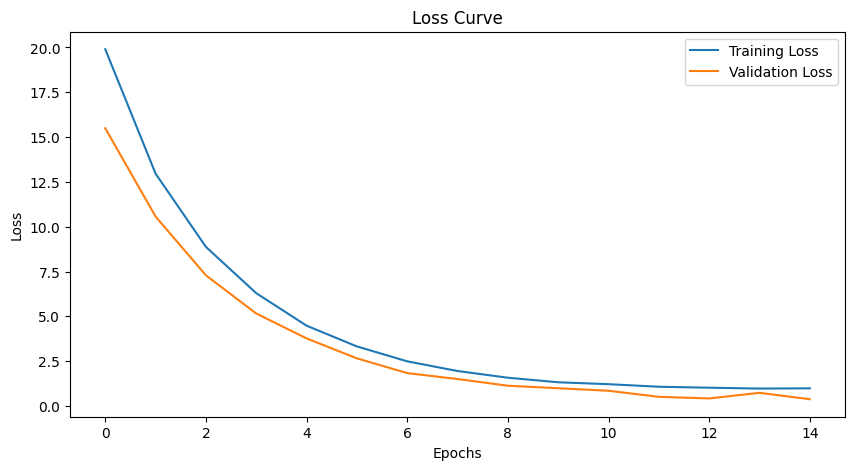

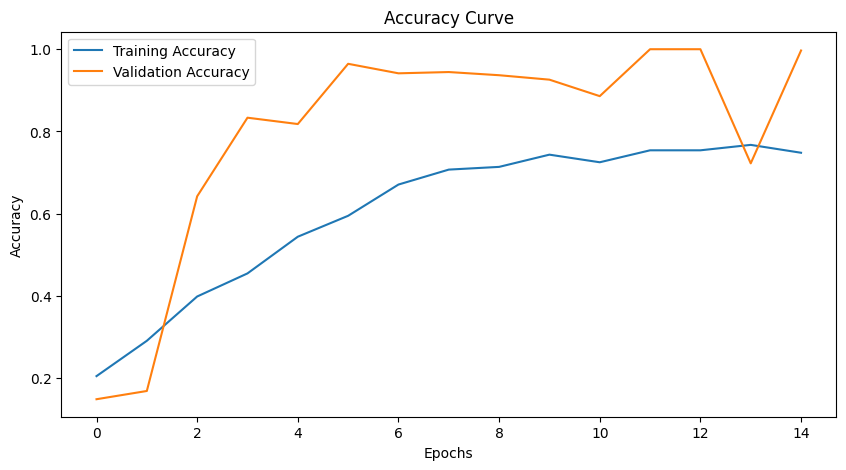

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title("Loss Curve")
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title("Accuracy Curve")
plt.show()

The validation accuracy tends to be higher than the testing accuracy, this could very likely be solved by using cross-validation. However, I did not mention it in the exam, thus I will not implement it. It's also likely that the model is overfitting to the validation set.

I also compared the model's predicted labels with the target labels.

In [ ]:
y_pred_prob = model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)

print("Predicted labels:", y_pred[:10])
print("True labels:", y_test[:10])

17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Predicted labels: [2 4 1 0 3 0 1 0 2 6]
True labels: [2 4 1 0 3 0 1 0 2 6]


In [ ]:
f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')

print(f"F1 Score (Macro): {f1_macro:.4f}")
print(f"F1 Score (Weighted): {f1_weighted:.4f}")

F1 Score (Macro): 0.9980
F1 Score (Weighted): 0.9981


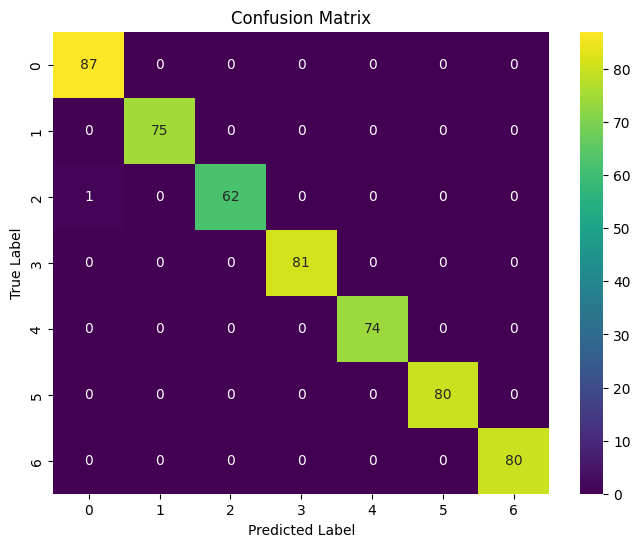

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='viridis', xticklabels=np.unique(y_test), yticklabels=np.unique(y_test))
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
report = classification_report(y_test, y_pred, target_names=[f"Class {i}" for i in np.unique(y_test)])
print("Classification Report:\n")
print(report)

Classification Report:

              precision    recall  f1-score   support

     Class 0       0.99      1.00      0.99        87
     Class 1       1.00      1.00      1.00        75
     Class 2       1.00      0.98      0.99        63
     Class 3       1.00      1.00      1.00        81
     Class 4       1.00      1.00      1.00        74
     Class 5       1.00      1.00      1.00        80
     Class 6       1.00      1.00      1.00        80

    accuracy                           1.00       540
   macro avg       1.00      1.00      1.00       540
weighted avg       1.00      1.00      1.00       540



# HYPERPARAMETER TUNING ACCORDING TO SECTION 5 OF THE EXAM

Now we can move on to hyperparameter tuning. I said in the exam that I would change around are: number of layers, number of
neurons, batch size, dropout rate and learning rate, therefore these are the ones I will tune those.

In [ ]:
def objective(trial):
    num_layers = trial.suggest_int("num_layers", 2, 4)
    num_neurons = trial.suggest_categorical("num_neurons", [32, 64, 128])
    batch_size = trial.suggest_categorical("batch_size", [16, 32, 64])
    dropout_rate = trial.suggest_float("dropout_rate", 0.4, 0.7)
    l2_strength = trial.suggest_float("l2_strength", 0.05, 0.3)
    learning_rate = trial.suggest_loguniform("learning_rate", 1e-4, 5e-3)

    model = Sequential([Input(shape=(X_train.shape[1],))])

    model.add(Dense(num_neurons, activation='relu', kernel_initializer='he_normal', kernel_regularizer=l2(l2_strength)))
    model.add(BatchNormalization())
    model.add(Dropout(dropout_rate))

    for _ in range(num_layers - 1):
        model.add(Dense(num_neurons, activation='relu', kernel_initializer='he_normal', kernel_regularizer=l2(l2_strength)))
        model.add(BatchNormalization())
        model.add(Dropout(dropout_rate))

    model.add(Dense(7, activation='softmax'))

    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss=CategoricalCrossentropy(),
                  metrics=['accuracy'])

    history = model.fit(
        X_train, tf.keras.utils.to_categorical(y_train),
        validation_data=(X_val, tf.keras.utils.to_categorical(y_val)),
        epochs=15,
        batch_size=batch_size,
        verbose=0
    )

    return max(history.history['val_accuracy'])

In [ ]:
study = optuna.create_study(direction="maximize")

study.optimize(objective, n_trials=10)

print("Best Hyperparameters:", study.best_params)

[I 2025-02-09 21:41:44,964] A new study created in memory with name: no-name-2e933906-a041-46c3-903e-773e06cb13de
<ipython-input-19-b7ecb95551f7>:7: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  learning_rate = trial.suggest_loguniform("learning_rate", 1e-4, 5e-3)
[I 2025-02-09 21:41:58,936] Trial 0 finished with value: 1.0 and parameters: {'num_layers': 4, 'num_neurons': 64, 'batch_size': 16, 'dropout_rate': 0.5881033507243294, 'l2_strength': 0.18186022615259229, 'learning_rate': 0.0022377201192016346}. Best is trial 0 with value: 1.0.
[I 2025-02-09 21:42:08,335] Trial 1 finished with value: 0.7067901492118835 and parameters: {'num_layers': 4, 'num_neurons': 32, 'batch_size': 64, 'dropout_rate': 0.4871254231418308, 'l2_strength': 0.18477629449048166, 'learning_rate': 0.0018285329796975415}. Best is trial 0 with value: 1.0.
[I 

Best Hyperparameters: {'num_layers': 4, 'num_neurons': 64, 'batch_size': 16, 'dropout_rate': 0.5881033507243294, 'l2_strength': 0.18186022615259229, 'learning_rate': 0.0022377201192016346}


We can now retrain the model using the best hyperparameters we found during tuning.

In [ ]:
best_params = study.best_params

final_model = Sequential([Input(shape=(X_train.shape[1],))])

final_model.add(Dense(best_params["num_neurons"], activation='relu', kernel_initializer='he_normal',
                      kernel_regularizer=l2(best_params["l2_strength"])))
final_model.add(BatchNormalization())
final_model.add(Dropout(best_params["dropout_rate"]))

for _ in range(best_params["num_layers"] - 1):
    final_model.add(Dense(best_params["num_neurons"], activation='relu', kernel_initializer='he_normal',
                          kernel_regularizer=l2(best_params["l2_strength"])))
    final_model.add(BatchNormalization())
    final_model.add(Dropout(best_params["dropout_rate"]))

final_model.add(Dense(7, activation='softmax'))

final_model.compile(optimizer=Adam(learning_rate=best_params["learning_rate"]),
                    loss=CategoricalCrossentropy(),
                    metrics=['accuracy'])

history = final_model.fit(
    X_train, tf.keras.utils.to_categorical(y_train),
    validation_data=(X_val, tf.keras.utils.to_categorical(y_val)),
    epochs=15,
    batch_size=best_params["batch_size"]
)

test_loss, test_accuracy = final_model.evaluate(X_test, tf.keras.utils.to_categorical(y_test))
print(f"Final Test Accuracy: {test_accuracy:.4f}")

Epoch 1/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.1910 - loss: 72.7694 - val_accuracy: 0.2932 - val_loss: 27.0723
Epoch 2/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4404 - loss: 20.7992 - val_accuracy: 0.3133 - val_loss: 9.3166
Epoch 3/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6730 - loss: 6.7398 - val_accuracy: 0.4259 - val_loss: 4.3065
Epoch 4/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7819 - loss: 2.9199 - val_accuracy: 0.9861 - val_loss: 2.1738
Epoch 5/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8032 - loss: 1.9625 - val_accuracy: 0.9259 - val_loss: 1.7190
Epoch 6/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7873 - loss: 1.6839 - val_accuracy: 1.0000 - val_loss: 1.1018
Epoch 7/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7667 - loss: 1.6107 - val_accuracy: 0.9012 - val_loss: 1.2712
Epoch 8/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7878 - loss: 1.6590 - val_accuracy: 0.9012 - val_lo

Now I'm going to evaluate the tuned model according to everything I specified earlier (as I wrote it in the exam).

In [ ]:
y_pred_prob = final_model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='weighted')
class_report = classification_report(y_test, y_pred, target_names=[f"Class {i}" for i in np.unique(y_test)])
conf_matrix = confusion_matrix(y_test, y_pred)

print(f"Accuracy Score: {accuracy:.4f}")
print(f"Weighted F1 Score: {f1:.4f}")
print("\nClassification Report:\n", class_report)

17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Accuracy Score: 0.9981
Weighted F1 Score: 0.9981

Classification Report:
               precision    recall  f1-score   support

     Class 0       0.99      1.00      0.99        87
     Class 1       1.00      0.99      0.99        75
     Class 2       1.00      1.00      1.00        63
     Class 3       1.00      1.00      1.00        81
     Class 4       1.00      1.00      1.00        74
     Class 5       1.00      1.00      1.00        80
     Class 6       1.00      1.00      1.00        80

    accuracy                           1.00       540
   macro avg       1.00      1.00      1.00       540
weighted avg       1.00      1.00      1.00       540



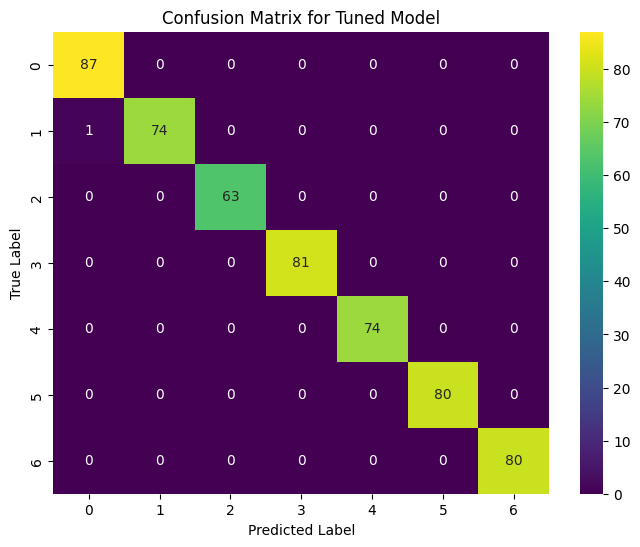

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='viridis', xticklabels=np.unique(y_test), yticklabels=np.unique(y_test))
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix for Tuned Model")
plt.show()

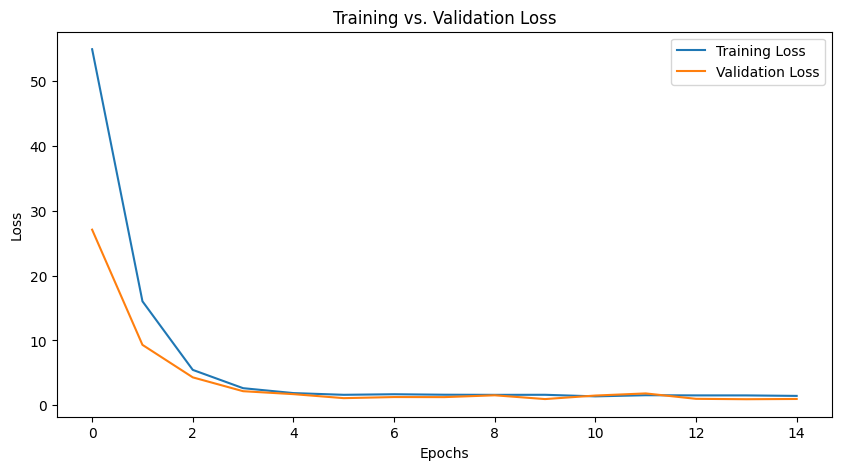

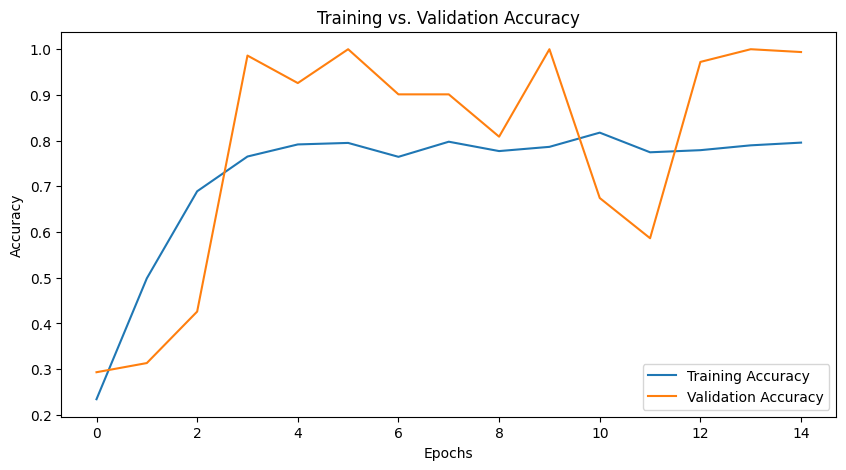

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title("Training vs. Validation Loss")
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title("Training vs. Validation Accuracy")
plt.show()

Overall, the model still shows overfitting issues due to the dataset. The steps that were taken to prevent it seem to impact learning negatively, however, this problem is difficult to solve without acting upon the leading cause (redundant features in the dataset).

At this point, I should add SHAP or LIME for interpretability (section 7 of the exam). However, I failed to mention them in the exam, therefore this is the last step.